In [1]:
from pathlib import Path
import pandas as pd

# Find the project root and dataset folder
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data" / "raw"

# List available files
for file in DATA_DIR.iterdir():
    print(file.name)

IMDB Dataset.csv


In [2]:
df=pd.read_csv(DATA_DIR/"IMDB Dataset.csv")
print("dataset shape: ", df.shape)
display(df.head(5))
print("Columns: ", df.columns.tolist())

dataset shape:  (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


Columns:  ['review', 'sentiment']


In [3]:
print(df.info())

print("\n Missing values: \n", df.isnull().sum())

print("\n Duplicated values: \n", df.duplicated().sum())

print("\n sentiment distribution: \n")
print(df["sentiment"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB
None

 Missing values: 
 review       0
sentiment    0
dtype: int64

 Duplicated values: 
 418

 sentiment distribution: 

sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [4]:
df=df.drop_duplicates().reset_index(drop=True)
print("shape after dropping duplicates: ", df.shape)
 
print("anymore duplicates: ",df.duplicated().sum())

shape after dropping duplicates:  (49582, 2)
anymore duplicates:  0


In [5]:
print("Duplicate review texts:", df["review"].duplicated().sum())

Duplicate review texts: 0


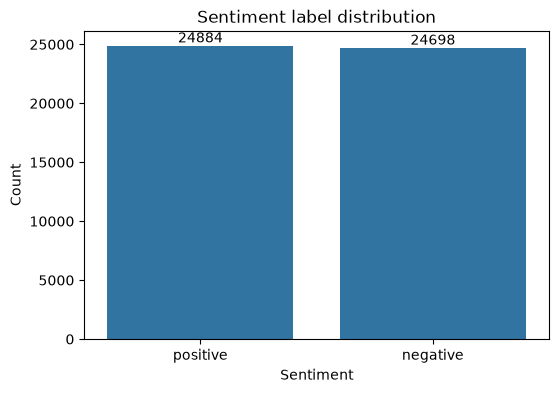

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
ax = sns.countplot(x='sentiment', data=df)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Sentiment label distribution")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.show()


Examine review lengths

In [7]:
df['review_length']=df['review'].str.split().str.len() #create a list or every item seperated by whitespace
print(df['review_length'].describe())

count    49582.000000
mean       231.350167
std        171.542020
min          4.000000
25%        126.000000
50%        173.000000
75%        281.000000
max       2470.000000
Name: review_length, dtype: float64


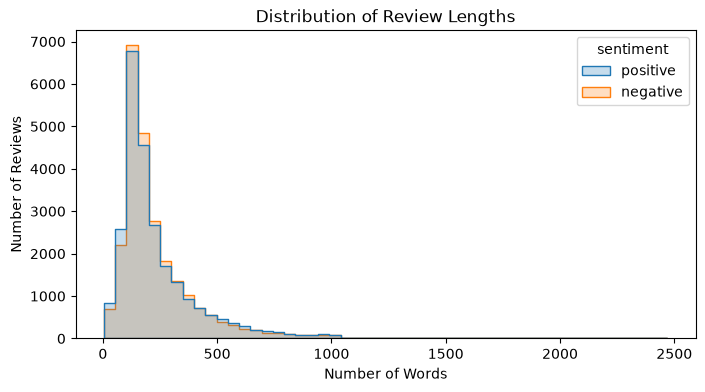

In [8]:
plt.figure(figsize=(8, 4))

sns.histplot(
    data=df,
    x="review_length",
    hue="sentiment",
    bins=50,
    element="step"
)

plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")

plt.show()

In [9]:
from sklearn.model_selection import train_test_split

X=df["review"]
y=df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf=TfidfVectorizer(max_features=20000,ngram_range=(1,2),min_df=2)

X_train_tfidf=tfidf.fit_transform(X_train)
X_test_tfidf=tfidf.transform(X_test)


In [11]:
print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

Training matrix shape: (39665, 20000)
Testing matrix shape: (9917, 20000)


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import time

lr_model=LogisticRegression(max_iter=1000,random_state=42)
start_time = time.time()
lr_model.fit(X_train_tfidf,y_train) #logistic regression in scikit learn auto handles the labels no need to encode.
training_time = time.time() - start_time
print(f"training completed in {training_time:.2f} seconds")

y_pred=lr_model.predict(X_test_tfidf)
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy: ",accuracy)

training completed in 2.26 seconds
Accuracy:  0.9030956942623778


classification report:



              precision    recall  f1-score   support

    negative       0.91      0.89      0.90      4940
    positive       0.89      0.92      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



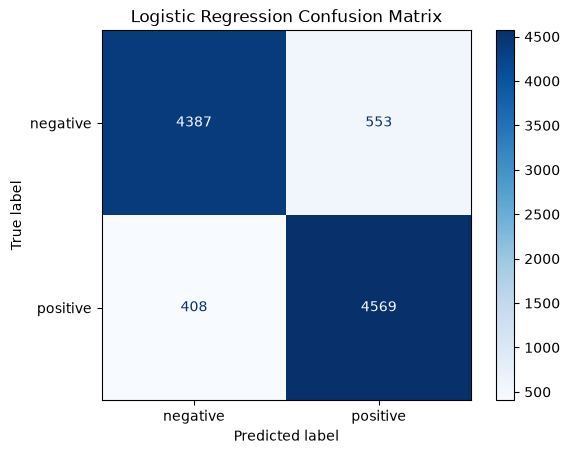

In [13]:
from sklearn.metrics import (classification_report,confusion_matrix,ConfusionMatrixDisplay)

print("classification report:\n")
print(classification_report(y_test,y_pred))
cm=confusion_matrix(y_test,y_pred,labels=["negative","positive"])
display=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["negative","positive"])
display.plot(cmap="Blues",values_format="d")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

test the model on some new reviews

In [14]:
custom_reviews = [
    "This movie was absolutely fantastic. I loved every minute.",
    "The acting was terrible and the story was boring.",
    "The movie was okay, but nothing special.",
    "I expected it to be bad, but it was surprisingly good.",
    "could be better "
]

custom_tfidf=tfidf.transform(custom_reviews)
custom_pred=lr_model.predict(custom_tfidf)
custom_probabilities = lr_model.predict_proba(custom_tfidf)

for review, sentiment, probabilities in zip(
    custom_reviews,
    custom_pred,
    custom_probabilities
):
    print(f"\nReview: {review}")
    print(f"Predicted sentiment: {sentiment}")
    print(f"Negative probability: {probabilities[0]:.3f}")
    print(f"Positive probability: {probabilities[1]:.3f}")


Review: This movie was absolutely fantastic. I loved every minute.
Predicted sentiment: positive
Negative probability: 0.160
Positive probability: 0.840

Review: The acting was terrible and the story was boring.
Predicted sentiment: negative
Negative probability: 0.983
Positive probability: 0.017

Review: The movie was okay, but nothing special.
Predicted sentiment: negative
Negative probability: 0.937
Positive probability: 0.063

Review: I expected it to be bad, but it was surprisingly good.
Predicted sentiment: positive
Negative probability: 0.459
Positive probability: 0.541

Review: could be better 
Predicted sentiment: negative
Negative probability: 0.818
Positive probability: 0.182


Error analysis

In [15]:
results=pd.DataFrame({
    "review":X_test.values,
    "actual_sentiment":y_test.values,
    "predicted_sentiment":y_pred,
})

In [16]:
misclassified=results[results["actual_sentiment"]!=results["predicted_sentiment"]]
print("Total test reviews: ",len(results))
print("incorrect predictions: ",len(misclassified))
print("Error rate: ",len(misclassified)/len(results))

misclassified.head()

Total test reviews:  9917
incorrect predictions:  961
Error rate:  0.09690430573762226


,review,actual_sentiment,predicted_sentiment
15,"This isn't exactly a great film, but I admire ...",positive,negative
24,Despite being a huge fan of Fred Astaire and G...,negative,positive
27,I'm both amused and disgusted by the people wh...,negative,positive
35,"Well, well....Roeg touched a bit of a nerve th...",positive,negative
43,"OK, let me again admit that I haven't seen any...",negative,positive


In [17]:
for _, row in misclassified.head(5).iterrows():
    print("Review:", row["review"][:500])
    print("Actual:", row["actual_sentiment"])
    print("Predicted:", row["predicted_sentiment"])
    print("-"*80)

Review: This isn't exactly a great film, but I admire the writers and director for trying something a little different. The film's main theme is fate and small, seemingly insignificant things that can greatly change the future. In some ways this reminds me of the film SLIDING DOORS, though instead of focusing on one random event, seemingly random stuff happens repeatedly and each one helps build to the cute conclusion. Plus, an odd bald guy seems to understand all this and he talks about this during one
Actual: positive
Predicted: negative
--------------------------------------------------------------------------------
Review: Despite being a huge fan of Fred Astaire and Ginger Rogers' movies, it wasn't until about 6 years ago that I first saw 'Follow the Fleet'. I knew all the songs from an old Astaire/Rogers record (yes, vinyl) but knew nothing of the plot.<br /><br />Unfortunately, while the songs are catchy and Ginger Rogers' character is sweet and funny, you just can't like 'Bake 

Support Vector Machine (Linear SVM) approach

In [18]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    random_state=42,
    max_iter=2000
)

start_time = time.time()
svm_model.fit(X_train_tfidf, y_train)
svm_training_time = time.time() - start_time
svm_pred = svm_model.predict(X_test_tfidf)
svm_accuracy = accuracy_score(y_test, svm_pred)

print(f"SVM Training Time: {svm_training_time:.2f} seconds")
print(f"SVM Accuracy: {svm_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, svm_pred))


SVM Training Time: 4.35 seconds
SVM Accuracy: 0.9016

Classification Report:
              precision    recall  f1-score   support

    negative       0.91      0.89      0.90      4940
    positive       0.89      0.91      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



compare the models

In [19]:
from IPython.display import display
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Linear SVM"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, svm_pred)
    ],
    "Training Time (seconds)": [
        training_time,
        svm_training_time
    ]
})

display(comparison)

,Model,Accuracy,Training Time (seconds)
0,Logistic Regression,0.903096,2.256287
1,Linear SVM,0.901583,4.345670


In [20]:
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score


lr_probabilities = lr_model.predict_proba(X_test_tfidf)[:, 1]
svm_scores = svm_model.decision_function(X_test_tfidf)

def evaluate_model(model_name, y_true, y_pred, y_score, training_time):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Macro)": precision_score(
            y_true, y_pred, average="macro"
        ),
        "Recall (Macro)": recall_score(
            y_true, y_pred, average="macro"
        ),
        "F1-Score (Macro)": f1_score(
            y_true, y_pred, average="macro"
        ),
        "ROC-AUC": roc_auc_score(
            (y_true == "positive").astype(int),
            y_score
        ),
        "Training Time (s)": training_time
    }


lr_results = evaluate_model("Logistic Regression",y_test,y_pred,lr_probabilities,training_time)
svm_results = evaluate_model("Linear SVM",y_test,svm_pred,svm_scores,svm_training_time)
comparison = pd.DataFrame([lr_results,svm_results])

display(comparison.round(4))

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),ROC-AUC,Training Time (s)
0,Logistic Regression,0.9031,0.9035,0.9030,0.9031,0.9655,2.2563
1,Linear SVM,0.9016,0.9017,0.9015,0.9016,0.9651,4.3457


Logistic Regression performs slightly better across all evaluation metrics.

# Final ML pipeline

In [21]:
from sklearn.pipeline import Pipeline

final_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2
    )),

    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

final_model.fit(X_train, y_train)
print("Pipeline training completed")

Pipeline training completed


In [22]:
pipeline_predictions = final_model.predict(X_test)

print("Pipeline Accuracy:",
      accuracy_score(y_test, pipeline_predictions))

print("\nClassification Report:")
print(classification_report(y_test, pipeline_predictions))

Pipeline Accuracy: 0.9030956942623778

Classification Report:
              precision    recall  f1-score   support

    negative       0.91      0.89      0.90      4940
    positive       0.89      0.92      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



model identifies positive reviews slightly better than negative reviews

In [23]:
import joblib

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)
model_path = model_dir / "sentiment_model.joblib"
joblib.dump(final_model, model_path)

print("Model saved successfully!")
print("Location:", model_path.resolve())

Model saved successfully!
Location: C:\Users\user\Desktop\reviewsense\models\sentiment_model.joblib


Test the model

In [24]:
loaded_model = joblib.load(model_path)

test_reviews = [
    "This movie was wonderful!",
    "Terrible movie.wasted my time.",
    "The acting was excellent and the story was engaging."
]

predictions = loaded_model.predict(test_reviews)
probabilities = loaded_model.predict_proba(test_reviews)

for review, prediction, probability in zip(
    test_reviews, predictions, probabilities
):
    print("\nReview:", review)
    print("Sentiment:", prediction)

    for label, score in zip(loaded_model.classes_, probability):
        print(f"{label}: {score:.3f}")


Review: This movie was wonderful!
Sentiment: positive
negative: 0.142
positive: 0.858

Review: Terrible movie.wasted my time.
Sentiment: negative
negative: 0.980
positive: 0.020

Review: The acting was excellent and the story was engaging.
Sentiment: positive
negative: 0.097
positive: 0.903
